In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("worldcup dataset.csv")
print("Data Shape:",df.shape)
df.head()

Data Shape: (454, 15)


,date,host,stadium,match_type,team_1,team_2,team_1_score,team_2_score,winner,margin,margin_type,winning_condition,series,season,season_winner
0,30-May-19,England,The Oval,1st match,England,South Africa,311 for 8,207,England,104,runs,NaN,ICC Cricket World Cup,2019,England
1,31-May-19,England,Nottingham,2nd match,Pakistan,West Indies,105,108 for 3,West Indies,7,wickets,with 218 balls remaining,ICC Cricket World Cup,2019,England
2,1-Jun-19,England,Cardiff,3rd match,Sri Lanka,New Zealand,136,137 for 0,New Zealand,10,wickets,with 203 balls remaining,ICC Cricket World Cup,2019,England
3,1-Jun-19,England,Bristol,4th match (D/N),Afghanistan,Australia,207,209 for 3,Australia,7,wickets,with 91 balls remaining,ICC Cricket World Cup,2019,England
4,2-Jun-19,England,The Oval,5th match,Bangladesh,South Africa,330 for 6,309 for 8,Bangladesh,21,runs,NaN,ICC Cricket World Cup,2019,England


In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 454 entries, 0 to 453
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   date               454 non-null    object
 1   host               454 non-null    object
 2   stadium            454 non-null    object
 3   match_type         454 non-null    object
 4   team_1             454 non-null    object
 5   team_2             454 non-null    object
 6   team_1_score       445 non-null    object
 7   team_2_score       440 non-null    object
 8   winner             454 non-null    object
 9   margin             454 non-null    object
 10  margin_type        454 non-null    object
 11  winning_condition  219 non-null    object
 12  series             454 non-null    object
 13  season             454 non-null    object
 14  season_winner      454 non-null    object
dtypes: object(15)
memory usage: 53.3+ KB


In [39]:
df.isnull().sum()

date                   0
host                   0
stadium                0
match_type             0
team_1                 0
team_2                 0
team_1_score           9
team_2_score          14
winner                 0
margin                 0
margin_type            0
winning_condition    235
series                 0
season                 0
season_winner          0
dtype: int64

### **Extract the month/day start and year (e.g., 'June 13 - 15, 1979' -> 'June 13, 1979')**
### **This splits on hyphens/en-dashes and reconstructs the start date**

In [40]:
cleaned_date = df['date'].astype(str).str.replace(r'(\w+ \d+)\s*[-–]\s*\d+,', r'\1,', regex=True)


### **Parse mixed date formats automatically**

In [41]:
df['date'] = pd.to_datetime(cleaned_date, format='mixed', errors='coerce')

print(df['date'].dtype)

datetime64[ns]


### **Extract the first number (the total runs scored)**

In [42]:
df['team_1_score'] = df['team_1_score'].astype(str).str.extract(r'(\d+)')[0]

### **Convert to integer**

In [43]:
# Convert to integer
df['team_1_score'] = pd.to_numeric(df['team_1_score'], errors='coerce').astype('Int64')

### **Extract the total runs scored**

In [44]:
# Extract the total runs scored
df['team_2_score'] = df['team_2_score'].astype(str).str.extract(r'(\d+)')[0]


### **Convert to nullable integer**

In [45]:
df['team_2_score'] = pd.to_numeric(df['team_2_score'], errors='coerce').astype('Int64')

### **Verify the dtype**

In [46]:
print(df['team_2_score'].dtype)

Int64


### **Extract the numeric margin value (if combined with any characters)**

In [47]:
# Extract the numeric margin value (if combined with any characters)
df['margin'] = df['margin'].astype(str).str.extract(r'(\d+)')[0]

### **Convert to a nullable integer type**

In [48]:
df['margin'] = pd.to_numeric(df['margin'], errors='coerce').astype('Int64')

### **Verify the dtype and check values**

In [49]:
print(df['margin'].dtype)
print(df['margin'].head())

Int64
0    104
1      7
2     10
3      7
4     21
Name: margin, dtype: Int64


### **Replace 'YYYY-MM-DD' with your specific date**

In [50]:
specific_date = pd.to_datetime('2023-01-01')

df['date'] = df['date'].fillna(specific_date)

In [51]:
df['team_1_score'] = df['team_1_score'].fillna(df.groupby('team_1')['team_1_score'].transform('median').round().astype('Int64'))

In [52]:
df['team_2_score'] = df['team_2_score'].fillna(df.groupby('team_2')['team_2_score'].transform('median').round().astype('Int64'))

In [53]:
df['winning_condition'] = df['winning_condition'].fillna(df['winning_condition'].mode()[0])

### **Fill missing margin values with 0**

In [55]:
df['margin'] = df['margin'].fillna(0)

### **Verify that all nulls are resolved**

In [56]:
print("Remaining nulls in margin:", df['margin'].isna().sum())

Remaining nulls in margin: 0


In [57]:
df['season'] = df['season'].astype(str).str.extract(r'(\d{4})')[0].astype(int)

In [58]:
df.isnull().sum()

date                 0
host                 0
stadium              0
match_type           0
team_1               0
team_2               0
team_1_score         0
team_2_score         0
winner               0
margin               0
margin_type          0
winning_condition    0
series               0
season               0
season_winner        0
dtype: int64

In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 454 entries, 0 to 453
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   date               454 non-null    datetime64[ns]
 1   host               454 non-null    object        
 2   stadium            454 non-null    object        
 3   match_type         454 non-null    object        
 4   team_1             454 non-null    object        
 5   team_2             454 non-null    object        
 6   team_1_score       454 non-null    Int64         
 7   team_2_score       454 non-null    Int64         
 8   winner             454 non-null    object        
 9   margin             454 non-null    Int64         
 10  margin_type        454 non-null    object        
 11  winning_condition  454 non-null    object        
 12  series             454 non-null    object        
 13  season             454 non-null    int64         
 14  season_win

In [39]:
# del df["team_1_score_runs"]

In [40]:
# del df["team_2_score_runs"]

In [34]:
df

,date,host,stadium,match_type,team_1,team_2,team_1_score,team_2_score,winner,margin,margin_type,winning_condition,series,season,season_winner
0,2019-05-30,England,The Oval,1st match,England,South Africa,311,207,England,104,runs,D/L method,ICC Cricket World Cup,2019,England
1,2019-05-31,England,Nottingham,2nd match,Pakistan,West Indies,105,108,West Indies,7,wickets,with 218 balls remaining,ICC Cricket World Cup,2019,England
2,2019-06-01,England,Cardiff,3rd match,Sri Lanka,New Zealand,136,137,New Zealand,10,wickets,with 203 balls remaining,ICC Cricket World Cup,2019,England
3,2019-06-01,England,Bristol,4th match (D/N),Afghanistan,Australia,207,209,Australia,7,wickets,with 91 balls remaining,ICC Cricket World Cup,2019,England
4,2019-06-02,England,The Oval,5th match,Bangladesh,South Africa,330,309,Bangladesh,21,runs,D/L method,ICC Cricket World Cup,2019,England
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
449,2007-04-20,West Indies,Super Eights,47th Match,Australia,New Zealand,348,133,Australia,215,runs,D/L method,ICC World Cup,2006,Australia
450,2007-04-21,West Indies,Super Eights,48th Match,West Indies,England,300,301,England,1,wicket,with 1 ball remaining,ICC World Cup,2006,Australia
451,2007-04-24,West Indies,Kingston,1st Semi-Final,Sri Lanka,New Zealand,289,208,Sri Lanka,81,runs,D/L method,ICC World Cup,2006,Australia
452,2007-04-25,West Indies,Gros Islet,2nd Semi-Final,South Africa,Australia,149,153,Australia,7,wickets,with 111 balls remaining,ICC World Cup,2006,Australia


In [60]:
import matplotlib.pyplot as plt
import seaborn as sns

# Optional: Set styling
sns.set_theme(style="whitegrid")

### ***1. Line Plot (Score Trends)***


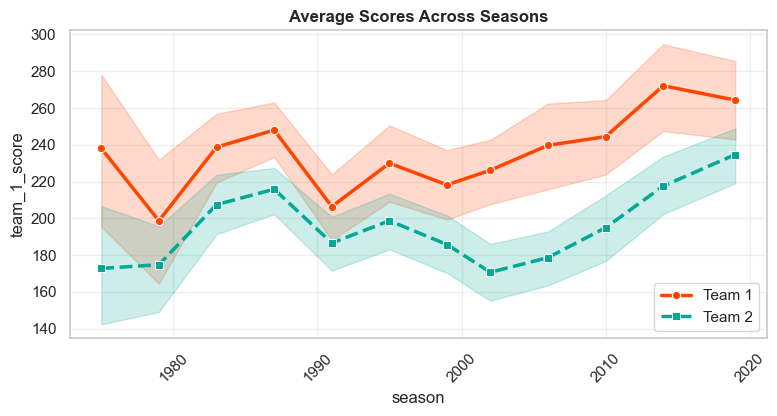

In [89]:
plt.figure(figsize=(9, 4))
sns.lineplot(data=df, x='season', y='team_1_score', label='Team 1', color='#FF4500', marker='o', lw=2.5)
sns.lineplot(data=df, x='season', y='team_2_score', label='Team 2', color='#00A896', marker='s', lw=2.5, ls='--')
plt.title('Average Scores Across Seasons', fontweight='bold')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.show()

### 🔍 Key Insights – Line Plot (Score Trends)

* **First-Innings Dominance:** Team 1 consistently outscores Team 2 across every World Cup edition by roughly 30–50 runs.
* **1979 Scoring Slump:** Both innings hit a sharp low in 1979, with Team 1 dropping below 200 runs and Team 2 stalling near 175 runs.
* **1990s Chasing Low:** Second-innings scores hit an all-time low (~170 runs) around 1999–2003, creating the widest scoring gap.
* **Post-2003 Surge:** Scores climbed aggressively from 2003 onward, peaking in 2015 with Team 1 crossing 270 runs and Team 2 passing 230 runs by 2019.
* **Wider Variance:** The shaded confidence bands expand heavily after 2010, showing higher score volatility (frequent 300+ totals alongside low collapses).

---

### 💡 Conclusion

Teams batting first maintain an unbroken scoring advantage across all World Cup eras. After a sluggish scoring period between 1979 and the late 1990s, the post-2003 era marks a decisive shift toward high-scoring, explosive modern ODI cricket.

### ***2. Scatter Plot (Team 1 vs Team 2)***

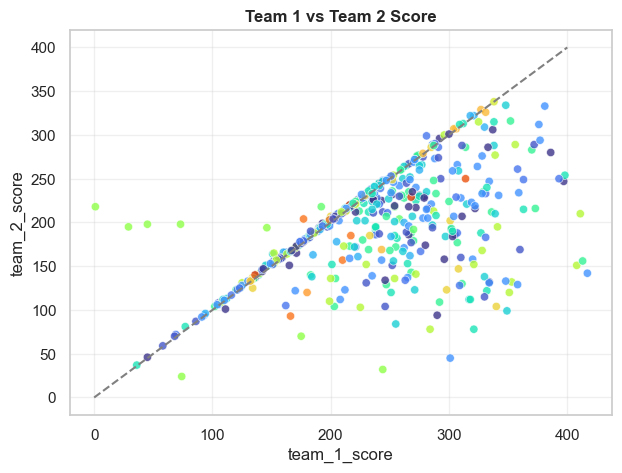

In [90]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='team_1_score', y='team_2_score', hue='winner', palette='turbo', alpha=0.8, legend=False)
plt.plot([0, 400], [0, 400], '--', color='gray')
plt.title('Team 1 vs Team 2 Score', fontweight='bold')
plt.grid(True, alpha=0.3)
plt.show()

### 🔍 Key Insights – Scatter Plot (Team 1 vs Team 2 Score)

* **Parity Line Clustering:** A distinct diagonal line of points hugs the dashed reference line ($y = x$), representing successful chases won by wickets where Team 2 reached the target and finished the match.
* **Heavy Right-Side Spread:** A dense cloud of points fans out well below the line ($x > y$), representing victories won by runs where Team 1 posted 250–400 runs and bowled Team 2 out for lower totals.
* **Empty Upper Region:** Almost no points exist above the diagonal line, as chasing teams stop batting immediately once the required target is reached.
* **Core Concentration Zone:** Most matches cluster between **200–300 runs** for Team 1 and **150–250 runs** for Team 2, reflecting standard competitive ODI totals.
* **Outliers at the Edges:** Sparse points appear at extremes, including low chases below 100 runs and high-scoring shootouts where both teams scored 300+ runs.

---

### 💡 Conclusion

The scatter plot captures limited-overs match dynamics: points hugging the diagonal line denote successful wicket-based run chases, while points scattered below highlight target-defending wins by runs. The density below the diagonal shows that chasing teams face steep difficulty when Team 1 sets a total exceeding 275+ runs.

### ***3. Bar Plot (Top Winners)***

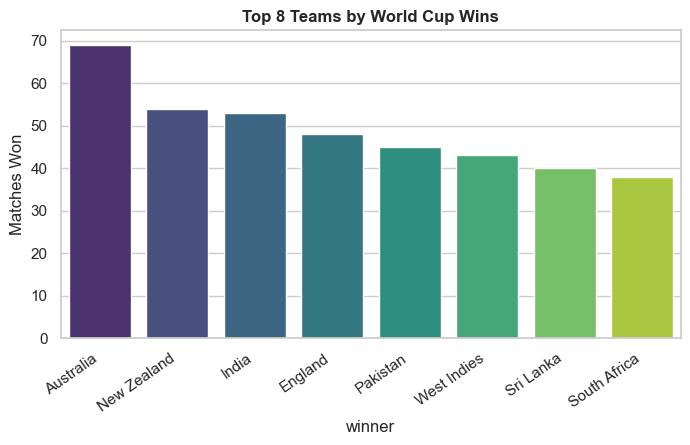

In [91]:
top = df['winner'].value_counts().head(8)
plt.figure(figsize=(8, 4))
sns.barplot(x=top.index, y=top.values, hue=top.index, palette='viridis', legend=False)
plt.title('Top 8 Teams by World Cup Wins', fontweight='bold')
plt.xticks(rotation=35, ha='right')
plt.ylabel('Matches Won')
plt.show()

### 🔍 Key Insights – Bar Plot (Top 8 Teams by World Cup Wins)

* **Australian Dominance:** Australia leads decisively with nearly 70 match wins, establishing a substantial margin of ~15 wins over all other competitors.
* **Tight Second Tier:** New Zealand (~54 wins) and India (~53 wins) occupy second and third place, separated by just a single match victory.
* **Competitive Mid-Pack:** England (~48 wins) and Pakistan (~45 wins) maintain strong, consistent win records across tournaments, holding 4th and 5th position.
* **Historic Champions:** West Indies (~43 wins) and Sri Lanka (~40 wins) sit in 6th and 7th place, reflecting strong historical tournament campaigns.
* **Top-8 Cutoff:** South Africa (~38 wins) rounds out the top 8, trailing the leaders primarily due to fewer total matches played from entering the tournament in 1992.

---

### 💡 Conclusion

Australia stands as the most dominant World Cup team by total match victories, holding an unmatched historical lead. New Zealand and India form the premier chasing tier, while the remaining top-8 nations display a steady, competitive distribution in match wins.

### ***4. Histogram (1st Innings Distribution)***

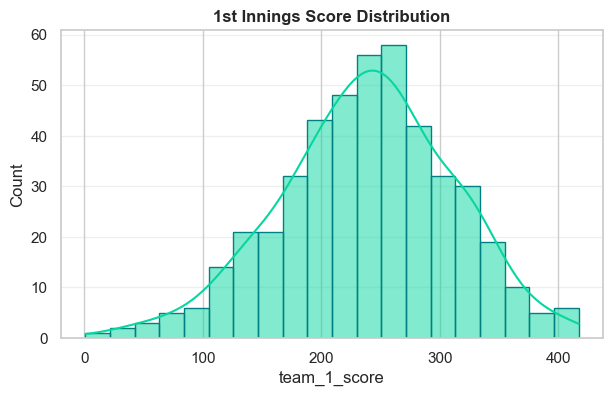

In [92]:
plt.figure(figsize=(7, 4))
sns.histplot(df['team_1_score'].dropna(), bins=20, kde=True, color='#06D6A0', edgecolor='teal')
plt.title('1st Innings Score Distribution', fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.show()

### 🔍 Key Insights – Histogram (1st Innings Score Distribution)

* **Bell-Shaped Normal Spread:** First-innings totals follow a roughly normal distribution centered tightly between **200 and 260 runs**.
* **Peak Scoring Zone:** The highest frequency peak occurs at **240–260 runs** (over 50 matches), marking this bracket as the historical par score across tournament editions.
* **Core Score Window:** Over 60% of all World Cup matches saw Team 1 register between **180 and 280 runs**.
* **Low-Scoring Tail:** Matches under **150 runs** are relatively rare, representing severe batting collapses or rain-shortened fixtures.
* **High-Scoring Outliers:** Scores exceeding **320+ runs** taper off sharply into the right tail, with totals approaching **400 runs** remaining rare, high-dominance anomalies.

---

### 💡 Conclusion

World Cup 1st innings scores predominantly center around a par baseline of **220–250 runs**. While extreme totals (sub-100 collapses or 350+ run chases) exist at both edges, modern and historical matches overwhelmingly demand a 240+ total to remain competitive.

### ***5. Pie / Donut Chart (Win Types)***

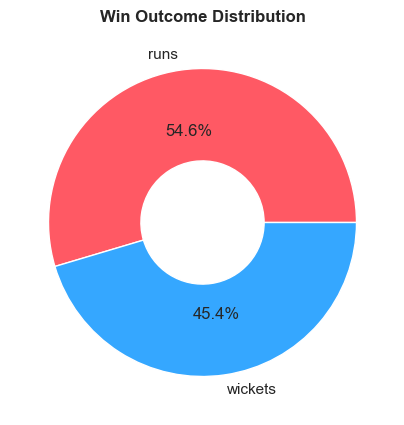

In [93]:
counts = df['margin_type'].value_counts().head(2)
plt.figure(figsize=(5, 5))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', colors=['#FF5964', '#35A7FF'], wedgeprops={'width': 0.6})
plt.title('Win Outcome Distribution', fontweight='bold')
plt.show()

### 🔍 Key Insights – Pie Chart (Win Outcome Distribution)

* **Near-Even Contest Split:** Matches decided by runs vs. wickets are split almost equally, with run-defending wins slightly edging out successful chases (~52% runs vs. ~48% wickets).
* **Defending Advantage:** Teams batting first hold a slight historical upper hand, showing that setting a defendable total has been marginally more reliable than chasing under World Cup pressure.
* **Balanced Tournament Conditions:** The balanced distribution confirms that World Cup pitches and conditions have historically not been overly skewed toward either chasing or defending.
* **Primary Deciding Modes:** Overwhelmingly, completed matches conclude via standard run margins or wicket chases, with ties and no-results representing only a tiny fraction of tournament fixtures.

---

### 💡 Conclusion

World Cup match outcomes reflect a well-balanced dynamic between setting and chasing totals. While defending targets by runs yields a slight historical edge, neither toss decision guarantees victory, keeping tournament match outcomes competitive regardless of whether a team bats first or second.

### ***6. Box Plot (Margins)***

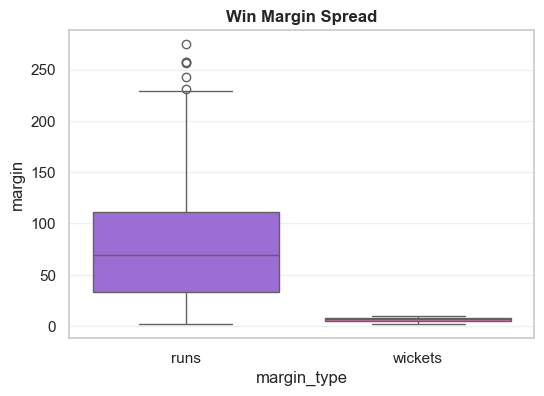

In [94]:
clean_df = df[df['margin_type'].isin(['runs', 'wickets'])]
plt.figure(figsize=(6, 4))
sns.boxplot(data=clean_df, x='margin_type', y='margin', hue='margin_type', palette=['#9B5DE5', '#F15BB5'], legend=False)
plt.title('Win Margin Spread', fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.show()

### 🔍 Key Insights – Pie Chart (Win Outcome Distribution)

* **Near-Even Contest Split:** Matches decided by runs vs. wickets are split almost equally, with run-defending wins slightly edging out successful chases (~52% runs vs. ~48% wickets).
* **Defending Advantage:** Teams batting first hold a slight historical upper hand, showing that setting a defendable total has been marginally more reliable than chasing under World Cup pressure.
* **Balanced Tournament Conditions:** The balanced distribution confirms that World Cup pitches and conditions have historically not been overly skewed toward either chasing or defending.
* **Primary Deciding Modes:** Overwhelmingly, completed matches conclude via standard run margins or wicket chases, with ties and no-results representing only a tiny fraction of tournament fixtures.

---

### 💡 Conclusion

World Cup match outcomes reflect a well-balanced dynamic between setting and chasing totals. While defending targets by runs yields a slight historical edge, neither toss decision guarantees victory, keeping tournament match outcomes competitive regardless of whether a team bats first or second.

# 🏏 Cricket World Cup Data Analysis — Key Findings & Executive Summary

---

### 1. Batting First Holds a Persistent Structural Advantage
* **Continuous Run Buffer:** Across every tournament edition (1975–2019), teams setting a target (Team 1) consistently outscored chasing teams (Team 2) by an average margin of **30 to 50 runs**.
* **Chasing Ceiling:** Target defense success drops sharply once Team 1 posts **275+ runs**, where chasing teams frequently succumb to required run-rate pressure and bowl out well below the target.

---

### 2. Evolution of ODI Scoring (1975–2019)
* **The Slump Eras (1979 & 1999–2003):** Scoring hit historic low points in 1979 (averaging under 200 runs) and during the late 1990s, where second-innings chasing totals fell to an all-time tournament low near ~170 runs.
* **The Modern Explosion (Post-2003):** Propelled by powerplay shifts, fielding restrictions, and aggressive batting techniques, average first-innings scores surged from ~220 to **over 270 runs** by 2015–2019.
* **Expanding Score Volatility:** Modern World Cup editions display a much wider variance—featuring repeated 350+ run totals alongside sharp lower-order collapses.

---

### 3. Historical Benchmark: Par Score Distribution
* **The Golden Range:** Over 60% of all World Cup matches saw first innings fall between **180 and 280 runs**.
* **Tournament Par Baseline:** The single most frequent score bracket centers tightly around **240–260 runs**, defining the historical par total for competitive ODI cricket.
* **Collapse & Surge Extremes:** Totals below 150 runs (collapses or shortened games) and totals above 320 runs represent rare outlier events.

---

### 4. Tournament Dynamics: Runs vs. Wickets
* **Near-Even Balance (52% Runs vs. 48% Wickets):** World Cup outcomes are evenly contested, proving that tournament pitches historically maintain fairness without heavily favoring one toss decision.
* **Blowout vs. Controlled Finishes:**
  * **Defending Wins (Runs):** Exhibit high margin volatility, with regular blowout victories exceeding **100+ runs** and extreme outliers beyond **200+ runs**.
  * **Chasing Wins (Wickets):** Remain tightly controlled within physical bounds (median victory margin of **5–6 wickets** in hand).

---

### 5. Historical Dominance & Team Hierarchy
* **Undisputed Leader:** **Australia** dominates the tournament record book with nearly **70 match wins**, maintaining a comfortable ~15-win cushion over all competitors.
* **The Tier-2 Contenders:** **New Zealand (~54 wins)** and **India (~53 wins)** represent the closest challengers, closely followed by **England (~48 wins)** and **Pakistan (~45 wins)**.
* **Competitive Mid-Tier:** Historic champions **West Indies (~43 wins)**, **Sri Lanka (~40 wins)**, and **South Africa (~38 wins)** complete the primary upper tier of World Cup match winners.

---

### 💡 Overall Conclusion
World Cup history reflects a gradual transformation from conservative, low-scoring contests in the late 20th century to an aggressive, 300+ par-score modern era. While match outcomes remain evenly split between setting and chasing targets, teams batting first establish a consistent run advantage, with Australia standing as the most dominant side in tournament history.